# 03 - Model Training & Evaluation
Time-based split use karte hain: purana data train, naya data test. Random split se future ki information train me chali jaati.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # notebook 'notebooks/' folder se chal raha hai
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config
sns.set_theme(style="whitegrid")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.preprocessing import build_training_frame
from src.model_utils import make_boosted_classifier
from src.train import time_based_split

df = build_training_frame()
train, test, cutoff = time_based_split(df)
X_train, y_train = train[config.FEATURES], train[config.COL_FAILURE]
X_test, y_test = test[config.FEATURES], test[config.COL_FAILURE]
print('cutoff:', cutoff, '| train', len(train), '| test', len(test))

cutoff: 2026-01-07 05:15:00 | train 7500 | test 2500


## Baselines

In [2]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=42, n_jobs=-1).fit(X_train, y_train)
for name, m in [('Logistic Regression', lr), ('Random Forest', rf)]:
    p = m.predict_proba(X_test)[:, 1]
    print(f'{name}: ROC-AUC={roc_auc_score(y_test, p):.3f} PR-AUC={average_precision_score(y_test, p):.3f}')

Logistic Regression: ROC-AUC=0.937 PR-AUC=0.491
Random Forest: ROC-AUC=0.977 PR-AUC=0.933


## Primary model (XGBoost agar installed hai, warna sklearn fallback)

In [3]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
model, algo = make_boosted_classifier(pos_weight)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print(algo)
print(classification_report(y_test, pred, target_names=['healthy', 'failure']))
print(confusion_matrix(y_test, pred))
print('ROC-AUC', roc_auc_score(y_test, prob), 'PR-AUC', average_precision_score(y_test, prob))

HistGradientBoosting (sklearn fallback)
              precision    recall  f1-score   support

     healthy       0.99      0.99      0.99      2367
     failure       0.91      0.89      0.90       133

    accuracy                           0.99      2500
   macro avg       0.95      0.94      0.95      2500
weighted avg       0.99      0.99      0.99      2500

[[2355   12]
 [  15  118]]
ROC-AUC 0.9777136122943607 PR-AUC 0.9368856596802154


## Threshold kaise choose karein
Missed failure (false negative) zyada costly hota hai, isliye threshold kam karne par recall badhta hai par false alarms bhi badhte hain.

In [4]:
from sklearn.metrics import precision_score, recall_score
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    p = (prob >= t).astype(int)
    rows.append({'threshold': t, 'precision': precision_score(y_test, p, zero_division=0), 'recall': recall_score(y_test, p)})
pd.DataFrame(rows).round(3)

,threshold,precision,recall
0,0.2,0.854,0.925
1,0.3,0.877,0.910
2,0.4,0.895,0.895
3,0.5,0.908,0.887
4,0.6,0.914,0.880
5,0.8,0.918,0.842


## Four models ka final comparison table

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
models = {
 'Logistic Regression': lr,
 'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42).fit(X_train, y_train),
 'Random Forest': rf,
 algo: model,
}
rows, probs = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]; probs[name] = p
    pr = (p >= 0.5).astype(int)
    rows.append({'model': name, 'precision': precision_score(y_test, pr), 'recall': recall_score(y_test, pr),
                 'f1': f1_score(y_test, pr), 'roc_auc': roc_auc_score(y_test, p), 'pr_auc': average_precision_score(y_test, p)})
comparison = pd.DataFrame(rows).round(3).set_index('model')
comparison

,precision,recall,f1,roc_auc,pr_auc
model,,,,,
Logistic Regression,0.170,0.970,0.289,0.937,0.491
Decision Tree,0.649,0.917,0.760,0.934,0.879
Random Forest,0.971,0.767,0.857,0.977,0.933
HistGradientBoosting (sklearn fallback),0.908,0.887,0.897,0.978,0.937


**Reading the table:** Logistic Regression ka recall high hai lekin precision bahut kam (bahut false alarms). Random Forest precision me best hai par recall kam. Boosted model dono me balance deta hai (best F1 aur PR-AUC), isliye primary model wahi hai.

## Confusion matrix (primary model)

True negatives=2355  False positives (false alarms)=12  False negatives (missed failures)=15  True positives=118


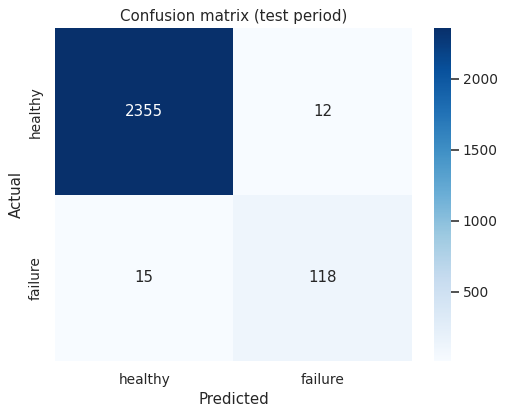

In [6]:
cm = confusion_matrix(y_test, (prob >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['healthy','failure'], yticklabels=['healthy','failure'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test period)'); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'True negatives={tn}  False positives (false alarms)={fp}  False negatives (missed failures)={fn}  True positives={tp}')

## ROC aur Precision-Recall curves

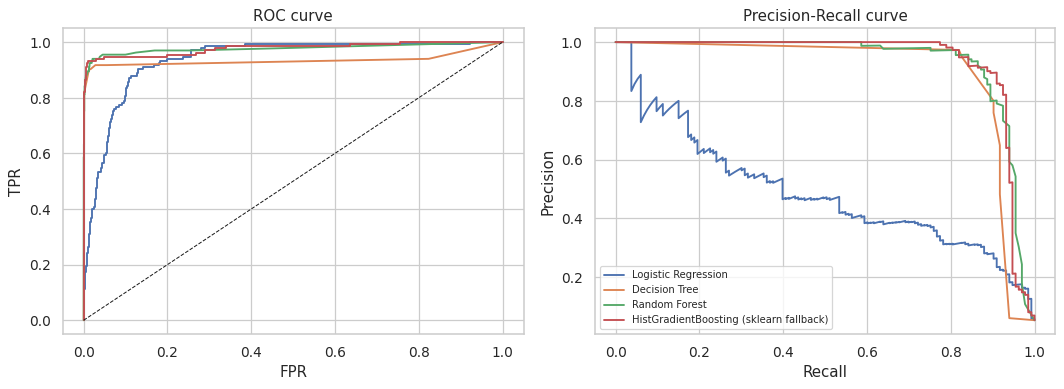

In [7]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=name)
    pr_, rc_, _ = precision_recall_curve(y_test, p); ax[1].plot(rc_, pr_, label=name)
ax[0].plot([0,1],[0,1],'k--', lw=.8); ax[0].set_title('ROC curve'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR')
ax[1].set_title('Precision-Recall curve'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

PR curve imbalanced data me ROC se zyada informative hoti hai, kyunki ROC me bahut saare healthy rows (true negatives) score ko achha dikha dete hain.

## Feature importance (permutation importance)
Test data me ek feature shuffle karke dekhte hain ki PR-AUC kitna girta hai.

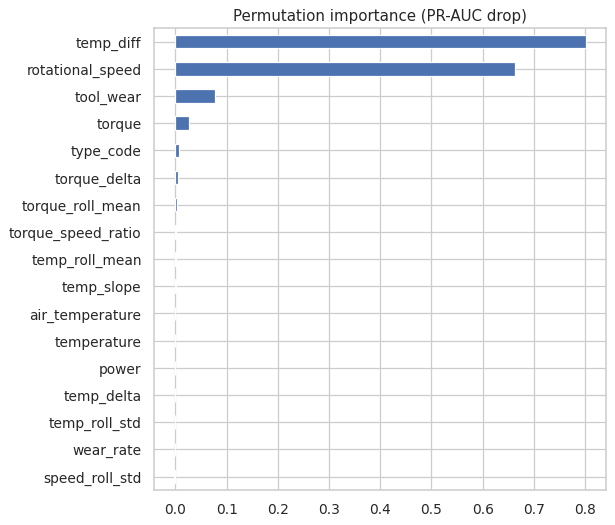

temp_diff           0.8017
rotational_speed    0.6637
tool_wear           0.0772
torque              0.0272
type_code           0.0068
dtype: float64

In [8]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(model, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=42)
imp = pd.Series(perm.importances_mean, index=config.FEATURES).sort_values()
imp.plot(kind='barh', figsize=(7,6)); plt.title('Permutation importance (PR-AUC drop)'); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(5).round(4)

## Learning curve (time-ordered)
Training data ka sirf pehla hissa (time ke hisaab se) leke model train karte hain aur wahi fixed test set par score dekhte hain. Isse pata chalta hai ki aur data se model improve hota hai ya nahi.

[0.899, 0.909, 0.919, 0.931, 0.937]


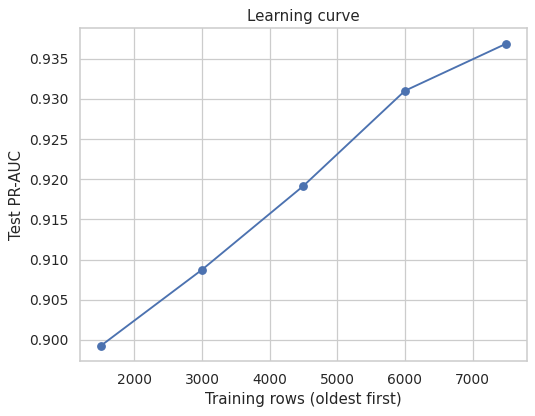

In [9]:
fracs = [0.2, 0.4, 0.6, 0.8, 1.0]
scores = []
for f in fracs:
    n = int(len(train) * f)
    tr = train.iloc[:n]
    yy = tr[config.COL_FAILURE].values
    pw = (yy == 0).sum() / max(1, (yy == 1).sum())
    m, _ = make_boosted_classifier(pw)
    m.fit(tr[config.FEATURES], yy)
    scores.append(average_precision_score(y_test, m.predict_proba(X_test)[:, 1]))
plt.plot([int(len(train)*f) for f in fracs], scores, marker='o')
plt.xlabel('Training rows (oldest first)'); plt.ylabel('Test PR-AUC'); plt.title('Learning curve'); plt.grid(True); plt.show()
print([round(s, 3) for s in scores])

## Failure-type model (sirf failure rows par)
Pehle version me ye model "No Failure" rows par bhi train hota tha, jisse weighted F1 majority class ki wajah se artificially high aata tha. Ab sirf `failure == 1` rows par train aur evaluate hota hai. Prediction pipeline:
1. Binary model: failure hoga ya nahi (probability)
2. Type model: agar risk high hai to kaunsa failure type zyada likely hai

In [10]:
from sklearn.metrics import classification_report
train_f = train[train[config.COL_FAILURE] == 1]; test_f = test[test[config.COL_FAILURE] == 1]
tm = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=42, n_jobs=-1)
tm.fit(train_f[config.FEATURES], train_f[config.COL_FAILURE_TYPE])
pred_t = tm.predict(test_f[config.FEATURES])
print(classification_report(test_f[config.COL_FAILURE_TYPE], pred_t, zero_division=0))

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.99      1.00      1.00       108
      Overstrain Failure       0.75      0.92      0.83        13
           Power Failure       1.00      1.00      1.00         2
          Random Failure       1.00      0.25      0.40         4
       Tool Wear Failure       0.80      0.67      0.73         6

                accuracy                           0.95       133
               macro avg       0.91      0.77      0.79       133
            weighted avg       0.96      0.95      0.95       133



## Anomaly detection (Isolation Forest) aur RUL ka quick check

In [11]:
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.metrics import mean_absolute_error
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42).fit(X_train[y_train == 0])
flag = (iso.predict(X_test) == -1).astype(int)
print('Anomalies flagged:', flag.sum(), '| precision', round(precision_score(y_test, flag), 3), '| recall', round(recall_score(y_test, flag), 3))
rr = RandomForestRegressor(n_estimators=150, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_train, train['rul'])
print('RUL MAE:', round(mean_absolute_error(test['rul'], rr.predict(X_test)), 2), '| mean-baseline MAE:', round(mean_absolute_error(test['rul'], [train['rul'].mean()]*len(test)), 2))

Anomalies flagged: 131 | precision 0.481 | recall 0.474
RUL MAE: 7.75 | mean-baseline MAE: 10.22


## Conclusions
- Time-based split + class weights + PR-AUC ke saath honest evaluation kiya.
- Boosted model sabse balanced hai (high recall + acceptable precision).
- Threshold 0.5 se kam karne par recall badhta hai par false alarms bhi; plant ki cost ke hisaab se threshold choose hota hai.
- Anomaly detector alag signal deta hai (unknown faults), RUL abhi experimental hai.